Ιστορική Αναδρομή: Από την Εξερεύνηση στην Κανονικοποίηση και Βελτιστοποίηση
1. Εξερεύνηση Δεδομένων (Exploratory Data Analysis)
Το αρχικό μας βήμα επικεντρώθηκε στην ανάλυση βασικών χαρακτηριστικών του dataset:

Μέγεθος Κειμένων (char_count, word_count, sentence_count): Μεγάλη διακύμανση (std > 6,000).
Πυκνότητα Παραπομπών (citation_density): Πολύ μικρές τιμές (~0.003 κατά μέσο όρο).
Ακραίες Τιμές (Outliers):
Εντοπίστηκαν εξαιρετικά μεγάλα κείμενα (133,561 χαρακτήρες).
Τεράστιες αποκλίσεις στη δομή (sentence_length_std > 200).
2. Κανονικοποίηση και Φιλτράρισμα
Κανονικοποίηση:
Με MinMaxScaler και StandardScaler, πετύχαμε την εξομάλυνση των χαρακτηριστικών.
Η χρήση λογαριθμικής κλίμακας ανέδειξε τις κατανομές, ειδικά για citation_density και avg_sentence_length.
Φιλτράρισμα Outliers:
Περιορίσαμε τις τιμές char_count ≤ 50,000 και sentence_count ≤ 500.
Η διακύμανση μειώθηκε σημαντικά.
3. Στρατηγική Ανάλυσης και Βελτιστοποίησης
Για το επόμενο βήμα, χρησιμοποιούμε τεχνικές όπως TF-IDF (Term Frequency-Inverse Document Frequency) και Binary Encoding (0,1 Matrix) για την ανάλυση των δεδομένων.

Πώς Βοηθούν οι Τεχνικές TF-IDF και Binary Encoding;
TF-IDF:

Υπολογίζει τη συχνότητα εμφάνισης λέξεων στο κείμενο.
Ενισχύει τη σημασία των σπάνιων, αλλά σημαντικών λέξεων.
Ιδανική για αναλυτικές εφαρμογές όπως clustering.
Binary Encoding (0,1 Matrix):

Δημιουργεί διακριτή αναπαράσταση χαρακτηριστικών (1 = Παρουσία, 0 = Απουσία).
Απλοποιεί την ανάλυση μεγάλων συνόλων δεδομένων.
Ενισχύει την ταχύτητα και την ακρίβεια σε αλγόριθμους μηχανικής μάθησης.

In [1]:
# Βιβλιοθήκες
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import Binarizer
import pandas as pd
import re

# 1. Φόρτωση δεδομένων
file_path = '../../data/raw/legal_text_classification.csv'  # Προσαρμόστε τη διαδρομή σας
df = pd.read_csv(file_path)

# 2. Αντιμετώπιση NaN τιμών
df['case_text'] = df['case_text'].fillna('')

# Δημιουργία καθαρισμένων δεδομένων (clean_feature_df)
df['char_count'] = df['case_text'].apply(len)  # Υπολογισμός χαρακτήρων
df['sentence_count'] = df['case_text'].apply(lambda x: len(re.findall(r'[.!?]', x)))  # Υπολογισμός προτάσεων

# 4. Καθαρισμός μηδενικών και μη έγκυρων τιμών
clean_feature_df = df[(df['char_count'] > 0) & (df['sentence_count'] > 0)]  # Φιλτράρισμα μηδενικών τιμών

# 5. Εφαρμογή TF-IDF
tfidf_vectorizer = TfidfVectorizer(max_features=500, stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(clean_feature_df['case_text'])

# 6. Μετατροπή TF-IDF σε DataFrame
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out())
display(tfidf_df.head())


# 7. Binary Encoding
binarizer = Binarizer(threshold=0.0)
binary_matrix = binarizer.fit_transform(tfidf_matrix.toarray())

# 8. Μετατροπή Binary Matrix σε DataFrame
binary_df = pd.DataFrame(binary_matrix, columns=tfidf_vectorizer.get_feature_names_out())
display(binary_df.head())

# 9. Στατιστική Περίληψη TF-IDF
tfidf_summary = tfidf_df.describe()
print("\nTF-IDF Summary:")
display(tfidf_summary)

# 10. Στατιστική Περίληψη Binary Encoding
binary_summary = binary_df.describe()
print("\nBinary Encoding Summary:")
display(binary_summary)


,10,11,12,13,14,15,16,17,18,19,...,view,visa,waived,waiver,wales,way,word,words,work,written
0,0.0,0.197537,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.197537,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.000000,0.0,0.0,0.0,0.144647,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,10,11,12,13,14,15,16,17,18,19,...,view,visa,waived,waiver,wales,way,word,words,work,written
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



TF-IDF Summary:


,10,11,12,13,14,15,16,17,18,19,...,view,visa,waived,waiver,wales,way,word,words,work,written
count,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,...,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000
mean,0.011148,0.010197,0.010333,0.009638,0.008693,0.009757,0.009639,0.008568,0.008872,0.008795,...,0.015887,0.007592,0.001319,0.002794,0.007394,0.011697,0.006138,0.009783,0.008130,0.005152
std,0.037682,0.036215,0.034138,0.035246,0.032049,0.037783,0.035444,0.031019,0.032665,0.034534,...,0.039387,0.047297,0.015328,0.028295,0.034195,0.033483,0.037004,0.041325,0.050827,0.026042
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,0.654700,0.807103,0.436775,0.625909,0.509832,0.613291,0.609206,0.423348,0.437021,0.727840,...,0.497898,0.800482,0.410928,0.705167,0.476107,0.398359,0.749228,0.720772,0.848513,0.561361



Binary Encoding Summary:


,10,11,12,13,14,15,16,17,18,19,...,view,visa,waived,waiver,wales,way,word,words,work,written
count,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,...,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000
mean,0.129047,0.117275,0.127031,0.109817,0.108043,0.110583,0.110139,0.107519,0.106430,0.101955,...,0.209595,0.040798,0.009393,0.013465,0.068696,0.161137,0.048337,0.093005,0.050030,0.062568
std,0.335258,0.321754,0.333014,0.312667,0.310441,0.313621,0.313069,0.309778,0.308394,0.302596,...,0.407028,0.197826,0.096465,0.115257,0.252941,0.367665,0.214482,0.290446,0.218012,0.242189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [2]:
# 1. Ανάλυση TF-IDF για λέξεις-κλειδιά που χαρακτηρίζουν κατηγορίες

# Υπολογισμός μέσης τιμής TF-IDF για κάθε λέξη
tfidf_means = tfidf_df.mean(axis=0)
top_tfidf_words = tfidf_means.sort_values(ascending=False).head(10)
bottom_tfidf_words = tfidf_means.sort_values(ascending=True).head(10)

# Εμφάνιση λέξεων με υψηλότερες και χαμηλότερες τιμές TF-IDF
top_tfidf_words, bottom_tfidf_words

# 2. Συσχέτιση TF-IDF και Binary Encoding για clustering

# Υπολογισμός συσχετίσεων μεταξύ TF-IDF και Binary Encoding
correlation_matrix = tfidf_df.corrwith(binary_df.mean(axis=0), axis=1)

# Επιλογή χαρακτηριστικών με ισχυρή θετική ή αρνητική συσχέτιση
high_corr_features = correlation_matrix[correlation_matrix > 0.5]
low_corr_features = correlation_matrix[correlation_matrix < -0.5]

# Επιστροφή χαρακτηριστικών
high_corr_features, low_corr_features

# 3. Συνδυασμός TF-IDF και Binary Encoding για βελτιστοποίηση

# Συνδυασμός σε νέο DataFrame
combined_features = pd.concat([tfidf_df, binary_df], axis=1)

# Επισκόπηση συνδυασμένων χαρακτηριστικών
combined_features_summary = combined_features.describe()
combined_features_summary


,10,11,12,13,14,15,16,17,18,19,...,view,visa,waived,waiver,wales,way,word,words,work,written
count,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,...,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000,24805.000000
mean,0.011148,0.010197,0.010333,0.009638,0.008693,0.009757,0.009639,0.008568,0.008872,0.008795,...,0.209595,0.040798,0.009393,0.013465,0.068696,0.161137,0.048337,0.093005,0.050030,0.062568
std,0.037682,0.036215,0.034138,0.035246,0.032049,0.037783,0.035444,0.031019,0.032665,0.034534,...,0.407028,0.197826,0.096465,0.115257,0.252941,0.367665,0.214482,0.290446,0.218012,0.242189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,0.654700,0.807103,0.436775,0.625909,0.509832,0.613291,0.609206,0.423348,0.437021,0.727840,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


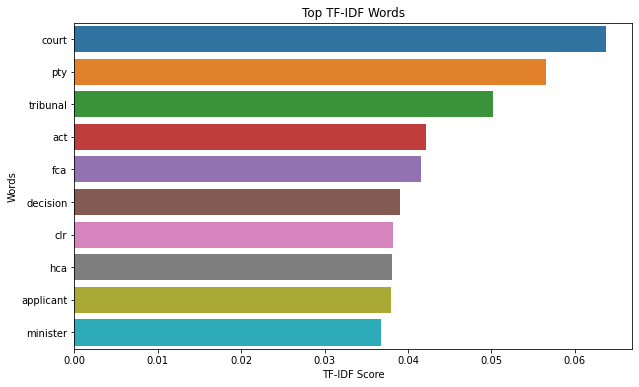

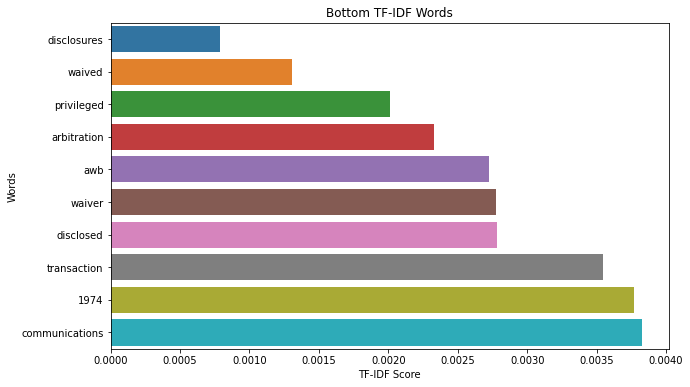

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
# Δημιουργία TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=500, stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(df['case_text'])  # Χρησιμοποιήστε τη σωστή στήλη από το DataFrame

# Χρήση της μεθόδου για εξαγωγή ονομάτων χαρακτηριστικών
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out())

# Υπολογισμός Top και Bottom TF-IDF λέξεων
top_tfidf_words = tfidf_df.mean().sort_values(ascending=False).head(10)
bottom_tfidf_words = tfidf_df.mean().sort_values(ascending=True).head(10)

# Συνάρτηση για γραφήματα
def plot_tfidf_words(title, words, values):
    plt.figure(figsize=(10, 6))
    sns.barplot(x=values, y=words)
    plt.title(title)
    plt.xlabel("TF-IDF Score")
    plt.ylabel("Words")
    plt.show()

# Γράφημα για τις Top TF-IDF λέξεις
plot_tfidf_words("Top TF-IDF Words", top_tfidf_words.index, top_tfidf_words.values)

# Γράφημα για τις Bottom TF-IDF λέξεις
plot_tfidf_words("Bottom TF-IDF Words", bottom_tfidf_words.index, bottom_tfidf_words.values)
